# SEC Filing Text: 10-K and 10-Q Paragraphs

**Owner:** Fatima Nasir · **Week 1** · NLP / sentiment · Code: `src/sec_filings.py`

**Goal:** collect 10-K and 10-Q filings from EDGAR and turn them into clean, labeled paragraphs ready for sentiment scoring in Week 2. Text source decision: `docs/news_source_comparison.md` (SEC filings first, news later).

**Before running:** add one line to a `.env` file in the repo root (the SEC asks every user to identify themselves):

```
SEC_USER_AGENT=RGBFS student project your_email@charlotte.edu
```

**What changed from the first draft** (`02_sec_filing_analysis.ipynb`, now replaced by this notebook and `src/sec_filings.py`):

1. **Microsoft 404 errors fixed.** The download URL took the company ID from the first part of the accession number. That is the ID of whoever *submitted* the filing, so filings sent through an agent (all four Microsoft filings) pointed at the wrong folder. The URL now uses the company's own ID.
2. **Alphabet filings.** Older filings are only in EDGAR's older index files. The listing now reads those files whenever their date range overlaps ours, and the counts below come from one consistent run (the draft's counts disagreed between cells).
3. **XBRL codes and checkboxes removed.** The draft's text started with hidden inline-XBRL codes ("nvda-20221030 0001045810 ...") and cover-page checkboxes. Those are now dropped before paragraphs are made, and each paragraph is tagged with its filing section (Item 1A risk factors, Item 7 or Item 2 MD&A, ...).
4. **Portable.** No hard-coded `C:\Users\...` paths; everything is relative to the repo and cached under `data/raw/sec/`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import sec_filings as sf

# Week 1 sample. Week 2 plan: widen to a broader set of S&P 500 firms and 2005 onward.
TICKERS = ["NVDA", "AAPL", "GOOGL", "MSFT", "AMZN"]
START, END = "2022-01-01", "2022-12-31"
FORMS = ("10-K", "10-Q")

filings, paras, problems = sf.build_corpus(TICKERS, START, END, forms=FORMS)
print(f"{len(filings)} filings, {len(paras):,} paragraphs, {len(problems)} problems")

C:\Users\LATITUDE\Downloads\RGBFS-connected\src\sec_filings.py:162: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(html, "lxml")


C:\Users\LATITUDE\Downloads\RGBFS-connected\src\sec_filings.py:162: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(html, "lxml")


C:\Users\LATITUDE\Downloads\RGBFS-connected\src\sec_filings.py:162: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(html, "lxml")


C:\Users\LATITUDE\Downloads\RGBFS-connected\src\sec_filings.py:162: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(html, "lxml")


C:\Users\LATITUDE\Downloads\RGBFS-connected\src\sec_filings.py:162: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(html, "lxml")


...

C:\Users\LATITUDE\Downloads\RGBFS-connected\src\sec_filings.py:162: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(html, "lxml")


C:\Users\LATITUDE\Downloads\RGBFS-connected\src\sec_filings.py:162: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(html, "lxml")


C:\Users\LATITUDE\Downloads\RGBFS-connected\src\sec_filings.py:162: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(html, "lxml")


C:\Users\LATITUDE\Downloads\RGBFS-connected\src\sec_filings.py:162: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(html, "lxml")


20 filings, 5,654 paragraphs, 0 problems


## 1. What we collected

In [2]:
print("Filings by company and form:")
display(filings.pivot_table(index="ticker", columns="form", values="accession", aggfunc="count", fill_value=0))

if len(problems):
    print("Filings that failed or produced no paragraphs:")
    display(problems)
else:
    print("Every filing downloaded and produced paragraphs.")

per_filing = paras.groupby(["ticker", "filing_date", "form"]).size().rename("paragraphs").reset_index()
display(per_filing)

Filings by company and form:


form,10-K,10-Q
ticker,,
AAPL,1,3
AMZN,1,3
GOOGL,1,3
MSFT,1,3
NVDA,1,3


Every filing downloaded and produced paragraphs.


,ticker,filing_date,form,paragraphs
0,AAPL,2022-01-28,10-Q,103
1,AAPL,2022-04-29,10-Q,106
2,AAPL,2022-07-29,10-Q,102
3,AAPL,2022-10-28,10-K,351
4,AMZN,2022-02-04,10-K,406
5,AMZN,2022-04-29,10-Q,256
6,AMZN,2022-07-29,10-Q,260
7,AMZN,2022-10-28,10-Q,257
8,GOOGL,2022-02-02,10-K,643
9,GOOGL,2022-04-27,10-Q,248


## 2. Quality checks

The checks look for the problems the first draft had. Each should print 0.

,count
"paragraphs with XBRL-style codes (us-gaap:, dei:, xbrli:)",0
paragraphs with checkbox symbols,0
empty paragraphs,0
exact duplicate paragraphs within a filing,54


Words per paragraph: median 54, 90th percentile 141, max 572


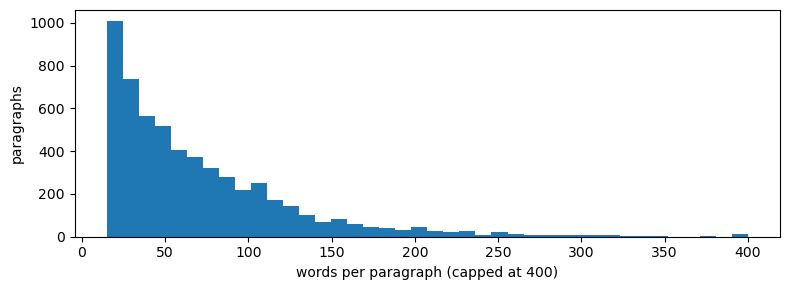

In [3]:
checks = {
    "paragraphs with XBRL-style codes (us-gaap:, dei:, xbrli:)": paras["text"].str.contains(r"\b(?:us-gaap|dei|xbrli|iso4217):", regex=True).sum(),
    "paragraphs with checkbox symbols": paras["text"].str.contains("[☐☒]", regex=True).sum(),
    "empty paragraphs": (paras["text"].str.strip() == "").sum(),
    "exact duplicate paragraphs within a filing": paras.duplicated(["accession", "text"]).sum(),
}
display(pd.Series(checks, name="count").to_frame())

words = paras["text"].str.split().str.len()
print(f"Words per paragraph: median {words.median():.0f}, 90th percentile {words.quantile(0.9):.0f}, max {words.max()}")
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(words.clip(upper=400), bins=40)
ax.set_xlabel("words per paragraph (capped at 400)"); ax.set_ylabel("paragraphs")
plt.tight_layout(); plt.show()

## 3. Sections

Risk factors are Item 1A in both forms. Management's discussion and analysis (MD&A) is Item 7 in a 10-K and Item 2 in a 10-Q. These are the sections most likely to carry sentiment about business conditions.

In [4]:
by_section = paras.groupby(["form", "section"]).size().rename("paragraphs").reset_index()
display(by_section.sort_values(["form", "paragraphs"], ascending=[True, False]))

mdna = paras[((paras["form"] == "10-K") & (paras["section"] == "Item 7")) |
             ((paras["form"] == "10-Q") & (paras["section"] == "Item 2"))]
risk = paras[paras["section"] == "Item 1A"]
print(f"MD&A paragraphs: {len(mdna):,}   Risk factor paragraphs: {len(risk):,}")
for name, df in [("Risk factors", risk), ("MD&A", mdna)]:
    if len(df):
        print(f"\nSample {name} paragraph ({df.iloc[0]['ticker']}, {df.iloc[0]['filing_date']}):")
        print(df.iloc[0]["text"][:600])

,form,section,paragraphs
16,10-K,Item 8,479
20,10-K,front matter,457
8,10-K,Item 1A,444
14,10-K,Item 7,353
0,10-K,Item 1,323
6,10-K,Item 15,184
15,10-K,Item 7A,41
12,10-K,Item 4,28
17,10-K,Item 9A,28
7,10-K,Item 16,11


MD&A paragraphs: 1,326   Risk factor paragraphs: 839

Sample Risk factors paragraph (NVDA, 2022-03-18):
In evaluating NVIDIA, the following risk factors should be considered in addition to the other information in this Annual Report on Form 10-K. Purchasing or owning NVIDIA common stock involves investment risks including, but not limited to, the risks described below. Any one of the following risks could harm our business, financial condition, results of operations or reputation, which could cause our stock price to decline, and you may lose all or a part of your investment. Additional risks, trends and uncertainties not presently known to us or that we currently believe are immaterial may also

Sample MD&A paragraph (NVDA, 2022-03-18):
The following discussion and analysis of our financial condition and results of operations should be read in conjunction with “Item 1A. Risk Factors”, our Consolidated Financial Statements and related Notes thereto, as well as other cautionary statemen

## 4. Save for Week 2

In [5]:
out = ROOT / "data" / "processed" / "sec"
out.mkdir(parents=True, exist_ok=True)
filings.to_csv(out / "filings.csv", index=False)
paras.to_parquet(out / "paragraphs.parquet", index=False)
problems.to_csv(out / "problems.csv", index=False)
print("Saved to", out.relative_to(ROOT), [f.name for f in sorted(out.iterdir())])

Saved to data\processed\sec ['filings.csv', 'paragraphs.parquet', 'problems.csv']


## 5. Notes and next steps

**Kept from the first draft (Fatima):**
* EDGAR is reliable and free to access with a proper User-Agent; all five companies' filing lists downloaded without errors.
* Risk-factor and MD&A text is the most relevant for stress. The draft's keyword search of Microsoft's October 2022 10-Q found 63 risk-related paragraphs (words like risk, uncertain, adverse).
* Filings are quarterly, so they cannot by themselves give daily warnings. They are best used as a slow-moving signal or combined with news later (see `docs/news_source_comparison.md`).

**Limitations:** five large technology firms in one year do not represent the market. Section tagging relies on "Item ..." headings and may miss unusual layouts; check `by_section` for filings where most text stays in "front matter".

**Next steps (Week 2):**
1. Widen the sample: more S&P 500 firms across sectors, from 2005 onward (the function takes any ticker list and date range).
2. Score paragraphs with the Loughran–McDonald finance word lists.
3. Have Salah spot-check about 20 scores by hand (team plan, Week 2).